# Практическая работа № 9. Метод опорных векторов — вариант C

**Цель:** оценить применимость линейного SVM на высокоразмерных данных и сопоставить его с ансамблевым методом.

В основной части используются русскоязычные отзывы RuReviews из ПР-6, TF-IDF-признаки, разреженная матрица и отложенная тестовая выборка. Дополнительно сравниваются времена обучения на нескольких размерах выборки и визуализируются границы решения на двумерном примере. Масштабирование выполняется внутри пайплайна SVM; TF-IDF обучается только на обучающей части.

In [49]:
import json
import re
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.datasets import make_moons
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import accuracy_score, f1_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import MaxAbsScaler, StandardScaler
from sklearn.svm import LinearSVC, SVC
from sklearn.inspection import DecisionBoundaryDisplay

RANDOM_STATE = 42
DATA_URL = (
    "https://raw.githubusercontent.com/"
    "sismetanin/rureviews/master/"
    "women-clothing-accessories.3-class.balanced.csv"
)
print("NumPy:", np.__version__)
print("pandas:", pd.__version__)

NumPy: 2.5.3
pandas: 3.0.6


## 1. Высокоразмерные данные: отзывы и TF-IDF

Датасет загружается из публичного источника ПР-6. Очистка оставляет русские буквы и пробелы. Сначала делим документы на train/test, затем обучаем TF-IDF только на train, чтобы тестовые документы не влияли на словарь и IDF.

In [50]:
df = pd.read_csv(DATA_URL, sep="\t", usecols=["review", "sentiment"])
df = df.dropna(subset=["review", "sentiment"]).copy()
df["review"] = df["review"].astype(str)
df["sentiment"] = df["sentiment"].astype(str)
df = df.drop_duplicates(subset=["review"])

def clean_text(text):
    text = text.lower()
    text = re.sub(r"<[^>]*>|https?://\S+|www\.\S+", " ", text)
    text = re.sub(r"[^а-яё\s]", " ", text)
    return " ".join(text.split())

df["clean_text"] = df["review"].map(clean_text)
df = df[df["clean_text"].str.len() > 0].copy()
print(f"Документов после очистки: {len(df):,}")
display(df["sentiment"].value_counts().rename("Число документов").to_frame())

Документов после очистки: 86,183


,Число документов
sentiment,
positive,28868
negative,28820
neautral,28495


In [51]:
X_train_text, X_test_text, y_train, y_test = train_test_split(
    df["clean_text"].to_numpy(),
    df["sentiment"].to_numpy(),
    test_size=0.2,
    random_state=RANDOM_STATE,
    stratify=df["sentiment"].to_numpy(),
)

vectorizer = TfidfVectorizer(
    max_features=10_000,
    min_df=2,
    max_df=0.95,
    ngram_range=(1, 2),
)
X_train = vectorizer.fit_transform(X_train_text)
X_test = vectorizer.transform(X_test_text)

print(f"Матрица train: {X_train.shape}; разреженная={hasattr(X_train, 'toarray')}")
print(f"Матрица test:  {X_test.shape}")
print(f"Число классов: {len(np.unique(y_train))}")

Матрица train: (68946, 10000); разреженная=True
Матрица test:  (17237, 10000)
Число классов: 3


## 2. Linear SVM и ансамбль на одинаковых TF-IDF-признаках

TF-IDF — разреженное представление. `MaxAbsScaler` масштабирует признаки, не создавая плотную матрицу; он находится в пайплайне и обучается только на train. Random Forest получает те же TF-IDF-признаки. Время в таблице — время обучения классификатора (векторизация измеряется отдельно).

In [52]:
svm_model = Pipeline([
    ("scaler", MaxAbsScaler()),
    ("classifier", LinearSVC(
        random_state=RANDOM_STATE,
        max_iter=10_000,
        class_weight="balanced",
    )),
])

start = time.perf_counter()
svm_model.fit(X_train, y_train)
svm_train_time = time.perf_counter() - start
svm_pred = svm_model.predict(X_test)

svm_result = {
    "Модель": "LinearSVC",
    "Accuracy": accuracy_score(y_test, svm_pred),
    "F1 macro": f1_score(y_test, svm_pred, average="macro"),
    "Время обучения, с": svm_train_time,
}
print(svm_result)

{'Модель': 'LinearSVC', 'Accuracy': 0.7240239020711261, 'F1 macro': 0.72375681506011, 'Время обучения, с': 3.203449000007822}


In [53]:
rf_model = RandomForestClassifier(
    n_estimators=50,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    class_weight="balanced_subsample",
)

start = time.perf_counter()
rf_model.fit(X_train, y_train)
rf_train_time = time.perf_counter() - start
rf_pred = rf_model.predict(X_test)

rf_result = {
    "Модель": "Random Forest (50 деревьев)",
    "Accuracy": accuracy_score(y_test, rf_pred),
    "F1 macro": f1_score(y_test, rf_pred, average="macro"),
    "Время обучения, с": rf_train_time,
}

results = pd.DataFrame([svm_result, rf_result]).sort_values(
    "F1 macro", ascending=False, ignore_index=True
)
display(results.round(4))

,Модель,Accuracy,F1 macro,"Время обучения, с"
0,LinearSVC,0.7240,0.7238,3.2034
1,Random Forest (50 деревьев),0.7161,0.7165,18.9606


## 3. Как время обучения зависит от размера выборки

Измеряем только время `fit` на уже построенных TF-IDF-признаках. Для каждого размера берём стратифицированные подвыборки и три повтора; на график наносится медиана. Это сравнение масштабирования на данном наборе, а не универсальная оценка асимптотической сложности.

In [54]:
candidate_sizes = [500, 1_000, 2_000, 5_000, 10_000, 20_000]
sample_sizes = [n for n in candidate_sizes if n <= X_train.shape[0]]
if len(sample_sizes) < 3:
    raise ValueError(
        f"Для эксперимента нужны минимум 3 размера выборки; доступно: {sample_sizes}"
    )

repeats = 3
svm_times = []
rf_times = []
for n in sample_sizes:
    svm_run_times = []
    rf_run_times = []
    for repeat in range(repeats):
        indices, _ = train_test_split(
            np.arange(len(y_train)),
            train_size=n,
            random_state=RANDOM_STATE + repeat,
            stratify=y_train,
        )
        X_sub = X_train[indices]
        y_sub = y_train[indices]

        svm_sub = Pipeline([
            ("scaler", MaxAbsScaler()),
            ("classifier", LinearSVC(
                random_state=RANDOM_STATE,
                max_iter=10_000,
                class_weight="balanced",
            )),
        ])
        start = time.perf_counter()
        svm_sub.fit(X_sub, y_sub)
        svm_run_times.append(time.perf_counter() - start)

        rf_sub = RandomForestClassifier(
            n_estimators=50,
            random_state=RANDOM_STATE,
            n_jobs=-1,
            class_weight="balanced_subsample",
        )
        start = time.perf_counter()
        rf_sub.fit(X_sub, y_sub)
        rf_run_times.append(time.perf_counter() - start)

    svm_times.append(float(np.median(svm_run_times)))
    rf_times.append(float(np.median(rf_run_times)))
    print(
        f"n={n:>6,}: LinearSVC={svm_times[-1]:.3f} с, "
        f"Random Forest={rf_times[-1]:.3f} с (медиана из {repeats})"
    )

n=   500: LinearSVC=0.010 с, Random Forest=0.139 с (медиана из 3)
n= 1,000: LinearSVC=0.018 с, Random Forest=0.190 с (медиана из 3)
n= 2,000: LinearSVC=0.041 с, Random Forest=0.274 с (медиана из 3)
n= 5,000: LinearSVC=0.105 с, Random Forest=0.596 с (медиана из 3)
n=10,000: LinearSVC=0.408 с, Random Forest=1.164 с (медиана из 3)
n=20,000: LinearSVC=0.653 с, Random Forest=2.728 с (медиана из 3)


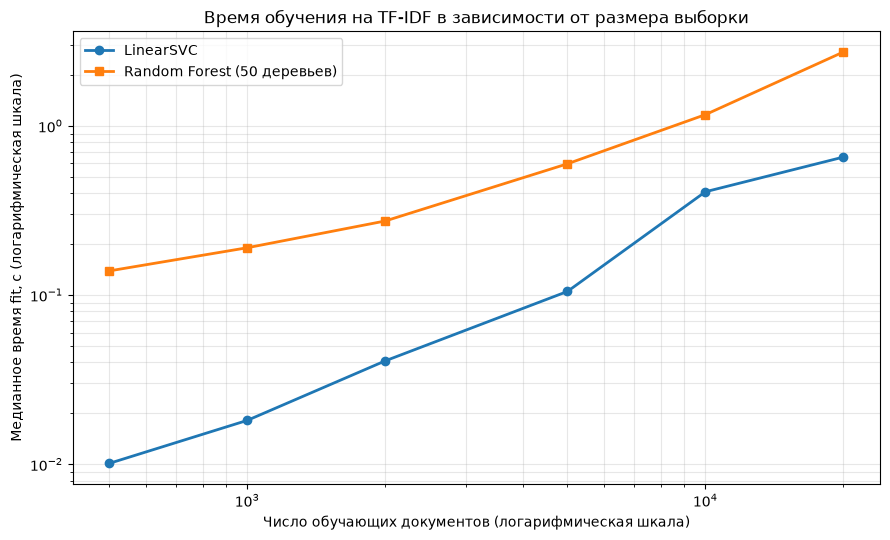

In [55]:
plt.figure(figsize=(9, 5.5))
plt.plot(sample_sizes, svm_times, "o-", linewidth=2, label="LinearSVC")
plt.plot(sample_sizes, rf_times, "s-", linewidth=2, label="Random Forest (50 деревьев)")
plt.xscale("log")
plt.yscale("log")
plt.xlabel("Число обучающих документов (логарифмическая шкала)")
plt.ylabel("Медианное время fit, с (логарифмическая шкала)")
plt.title("Время обучения на TF-IDF в зависимости от размера выборки")
plt.grid(True, which="both", alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig("../scaling_plot.png", dpi=150, bbox_inches="tight")
plt.show()

## 4. Границы решения и влияние C на двумерном примере

Для наглядной визуализации используем `make_moons`. Масштабирование и SVC находятся в пайплайне. Сравниваем линейную границу с RBF при двух значениях `C`; gamma оставляем равной `scale`, чтобы отдельно увидеть влияние C.

In [56]:
X_2d, y_2d = make_moons(n_samples=500, noise=0.25, random_state=RANDOM_STATE)
X_2d_train, X_2d_test, y_2d_train, y_2d_test = train_test_split(
    X_2d,
    y_2d,
    test_size=0.25,
    random_state=RANDOM_STATE,
    stratify=y_2d,
)

boundary_models = {
    "Линейное, C=1": Pipeline([
        ("scaler", StandardScaler()),
        ("svc", SVC(kernel="linear", C=1.0)),
    ]),
    "RBF, C=0.1": Pipeline([
        ("scaler", StandardScaler()),
        ("svc", SVC(kernel="rbf", C=0.1, gamma="scale")),
    ]),
    "RBF, C=10": Pipeline([
        ("scaler", StandardScaler()),
        ("svc", SVC(kernel="rbf", C=10, gamma="scale")),
    ]),
}

boundary_scores = {}
for name, model in boundary_models.items():
    model.fit(X_2d_train, y_2d_train)
    boundary_scores[name] = accuracy_score(y_2d_test, model.predict(X_2d_test))
    print(f"{name}: accuracy на test={boundary_scores[name]:.3f}")

Линейное, C=1: accuracy на test=0.824
RBF, C=0.1: accuracy на test=0.888
RBF, C=10: accuracy на test=0.936


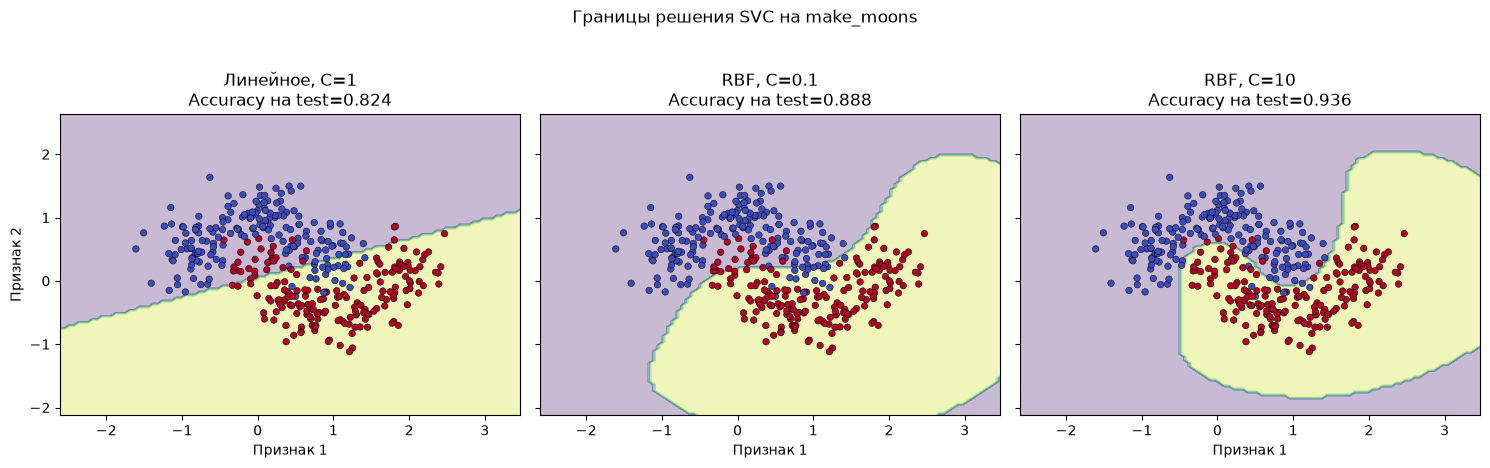

In [57]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharex=True, sharey=True)
for ax, (name, model) in zip(axes, boundary_models.items()):
    DecisionBoundaryDisplay.from_estimator(
        model,
        X_2d_train,
        response_method="predict",
        plot_method="contourf",
        alpha=0.3,
        ax=ax,
    )
    ax.scatter(
        X_2d_train[:, 0],
        X_2d_train[:, 1],
        c=y_2d_train,
        cmap="coolwarm",
        edgecolors="black",
        linewidths=0.35,
        s=22,
    )
    ax.set_title(f"{name}\nAccuracy на test={boundary_scores[name]:.3f}")
    ax.set_xlabel("Признак 1")
axes[0].set_ylabel("Признак 2")
fig.suptitle("Границы решения SVC на make_moons", y=1.03)
fig.tight_layout()
plt.show()

## Выводы

- Линейный SVM применим к большим разреженным TF-IDF-матрицам: он работает непосредственно с sparse-признаками, а стандартизация без центрирования не требует их уплотнять.
- Сопоставьте в таблице Macro-F1 и время `fit`: для выбора между SVM и Random Forest важны не только метрики, но и ограничения по памяти/времени. Random Forest здесь является ансамблевым базовым методом; это не утверждение о превосходстве модели на любых данных.
- График замеров показывает фактический рост времени на выбранных размерах и реализации. Не следует трактовать наклон нескольких точек как точную асимптотическую сложность.
- SVM обычно предпочтителен для малых и средних наборов с большим числом разреженных признаков, особенно при близких метриках и ограниченном времени/памяти. Kernel SVM может стать непрактичным на больших выборках из-за затрат на попарные взаимодействия; даже линейный SVM не гарантирует лучшего качества и может проигрывать ансамблям на нелинейных табличных данных.
- На `make_moons` RBF способен описывать нелинейную границу, в отличие от линейного ядра. При увеличении `C` штраф за ошибки на обучении растёт, что может сделать границу более сложной; результат на тесте и графики показывают, полезно ли это для данного примера.

In [58]:
summary = {
    "dataset": {
        "name": "RuReviews 3-class balanced",
        "n_samples": int(len(df)),
        "n_features": int(X_train.shape[1]),
        "train_samples": int(X_train.shape[0]),
        "test_samples": int(X_test.shape[0]),
    },
    "models": results.to_dict(orient="records"),
    "scaling_experiment": {
        "sample_sizes": sample_sizes,
        "repeats": repeats,
        "svm_median_seconds": svm_times,
        "random_forest_median_seconds": rf_times,
    },
    "make_moons": {
        "test_accuracy": boundary_scores,
        "parameters": {
            "linear": {"kernel": "linear", "C": 1.0},
            "rbf_low_C": {"kernel": "rbf", "C": 0.1, "gamma": "scale"},
            "rbf_high_C": {"kernel": "rbf", "C": 10.0, "gamma": "scale"},
        },
    },
}
output_path = Path("../results_summary.json")
output_path.parent.mkdir(parents=True, exist_ok=True)
output_path.write_text(
    json.dumps(summary, ensure_ascii=False, indent=2),
    encoding="utf-8",
)
print(f"Результаты сохранены: {output_path.resolve()}")

Результаты сохранены: C:\Users\user\Desktop\projects\MLProjectsCS32\pr09-svm\results_summary.json
